# D4 corrections with MCAMS (and pycorrect for comparison)

Synthetic example: **Ni powder in a vanadium container, inside a furnace**, measured on D4 at
λ = 0.5 Å. The five regrouped measurements (output of `d4creg`), each in `.adat` (2θ, I, σ) and
`.qdat` (Q, I, σ), are in `data/`:

| file | measurement | configuration |
|---|---|---|
| `I_SCE` | sample in container in environment | `sc` (+ furnace as background) |
| `I_CE` | empty container in environment | `c` |
| `I_E` | empty environment | background |
| `I_VE` | vanadium rod in environment | `v` |
| `I_ACE` | ¹⁰B powder (black absorber) in container in environment | background |

The experiment is described in `Ni_powder.par` (sample-description file). The data were made by
`make_synthetic_data.py`, which also wrote the true values (`data/truth_*.dat`).

**What this notebook does**
1. reads the data (angle or Q scale);
2. computes with **MCAMS** the Paalman & Pings factors $A_{b,C}$, the multiple-scattering ratios
   $\delta_C$ and the transmissions $T_C$;
3. makes the subtraction **step by step** to get $I_S$ (sample) and $I_V$ (vanadium), then
   $d\sigma/d\Omega$ and $S(Q)$; checks it against `run_correction` (one line) and the truth;
4. saves everything on the **Q and angle** scales (`results/`);
5. (optional) does the same with **pycorrect** (CORRECT 2.24) for comparison.

Conventions: body `s` sample, `c` container, `v` vanadium; configuration = bodies in the beam
(e.g. `sc`). The furnace is treated as background (ToScaNA's default `environment="background"`);
the vanadium was measured in the same furnace.

In [1]:
import contextlib, io, math, os, time
import numpy as np
import matplotlib.pyplot as plt

import toscana_path          # this ToScaNA as `toscana` (before any toscana import)
from toscana.dataio.running_params import getRunningParams
from toscana.experiment.measurement import Measurement
from toscana.workflows.correction import read_regrouped, run_correction, structure_factor, save_structure_factor
from toscana.corrections.setup import setups_from_measurement
from toscana.corrections.factors import compute_factors
from toscana.corrections.pycorrect.correct_2axis import placzek
from toscana.isotopes import Element

INPUT = "adat"               # "adat" (2theta) or "qdat" (Q): both give the same result
RESULTS = "results"
os.makedirs(RESULTS, exist_ok=True)
%matplotlib inline
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True})

## 1. The experiment and the data

Ni_powder: lambda = 0.5 A, 1069 points, input scale: angle
sample: {'Ni': 1.0}, effective density 0.04572 at/A^3 (packing 0.500)


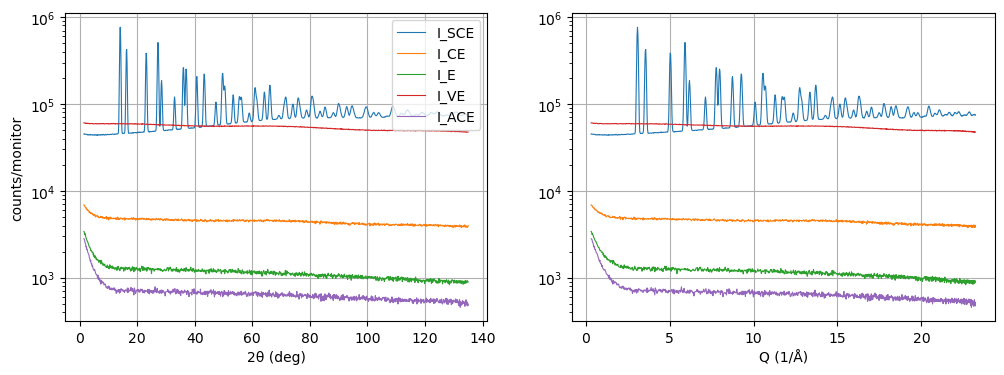

In [2]:
with contextlib.redirect_stdout(io.StringIO()):          # Measurement prints a summary
    m = Measurement(getRunningParams("Ni_powder.par"))
lam = m.wavelength
names = {"sample": "I_SCE", "container": "I_CE", "environment": "I_E",
         "vanadium": "I_VE", "absorber": "I_ACE"}
files = {k: f"data/{n}.{INPUT}" for k, n in names.items()}
files["empty"] = files["environment"]                    # background: the empty environment

data = {}
for key, path in files.items():
    theta, y, e, scale = read_regrouped(path, lam)     # Q is converted to 2theta
    data[key] = (theta, y, e)
theta = data["sample"][0]
q = 4 * math.pi / lam * np.sin(np.radians(theta) / 2)
print(f"{m.Title}: lambda = {lam} A, {len(theta)} points, input scale: {scale}")
print(f"sample: {m.conc}, effective density {m.EffAtomicDensity:.5f} at/A^3 (packing {m.PackingFraction:.3f})")

fig, ax = plt.subplots(1, 2)
for key, n in names.items():
    ax[0].plot(theta, data[key][1], lw=0.8, label=n)
    ax[1].plot(q, data[key][1], lw=0.8, label=n)
ax[0].set(xlabel="2θ (deg)", ylabel="counts/monitor", yscale="log")
ax[1].set(xlabel="Q (1/Å)", yscale="log"); ax[0].legend(); plt.show()

## 2. Set-up, attenuation factors and multiple scattering (MCAMS)

`setups_from_measurement` describes the experiment as concentric cylinders (from the `.par`
file: `<Sshape>`, `<Cshape>`, `<Nshape>`, optional `<LayNN>` layers for more walls or shields).
`compute_factors` gives, for every configuration $C$ and body $b$:
- $A_{b,C}(2\theta)$: Paalman & Pings factor (MCAMS, direct integration);
- $\delta_C(2\theta)$: multiple / single scattering of the configuration (MCAMS Monte Carlo,
  isotropic scatterers);
- $T_C$: transmission of the beam (exact);
- $n\langle L\rangle_b$ (atoms per beam area) and $P_b=\sum\rho\sigma_s\langle L\rangle$
  (scattering power).

With the default statistics this takes about 10 s here.

In [3]:
sample_setup, vanadium_setup = setups_from_measurement(m, environment="background")
for setup, label in ((sample_setup, "sample set-up"), (vanadium_setup, "vanadium set-up")):
    print(label)
    for l in setup.layers:
        print(f"   {l.name:10s} body {l.body}: d = {l.inner_diam}-{l.outer_diam} mm, h = {l.height} mm, "
              f"mu = {l.mu(lam):.4f} 1/mm, scattering fraction {l.scatter_fraction(lam):.3f}")

t0 = time.time()
fs = compute_factors(sample_setup, theta)          # MCAMS: n_points=1e5, ms_particles=2e6, seed=1
fv = compute_factors(vanadium_setup, theta)
print(f"\nfactors computed in {time.time() - t0:.1f} s")
print("configurations:", fs.configurations, fv.configurations)
print("transmissions :", {k: round(v, 4) for k, v in {**fs.T, **fv.T}.items()})
print("n<L> (at/A^3 mm):", {k: round(v, 5) for k, v in {**fs.atoms_per_area, **fv.atoms_per_area}.items()})
print("P (b at/A^3 mm) :", {k: round(v, 5) for k, v in {**fs.scattering_power, **fv.scattering_power}.items()})

sample set-up
   sample     body s: d = 0.0-5.0 mm, h = 60.0 mm, mu = 0.0903 1/mm, scattering fraction 0.937
   container  body c: d = 5.0-5.2 mm, h = 60.0 mm, mu = 0.0471 1/mm, scattering fraction 0.783
vanadium set-up
   vanadium   body v: d = 0.0-6.08 mm, h = 60.0 mm, mu = 0.0471 1/mm, scattering fraction 0.783



factors computed in 10.2 s
configurations: ['c', 'sc'] ['v']
transmissions : {'T_c': 0.9907, 'T_sc': 0.8086, 'T_v': 0.8483}
n<L> (at/A^3 mm): {'c': 0.01447, 's': 0.11222, 'v': 0.26214}
P (b at/A^3 mm) : {'c': 0.07384, 's': 2.07611, 'v': 1.33812}


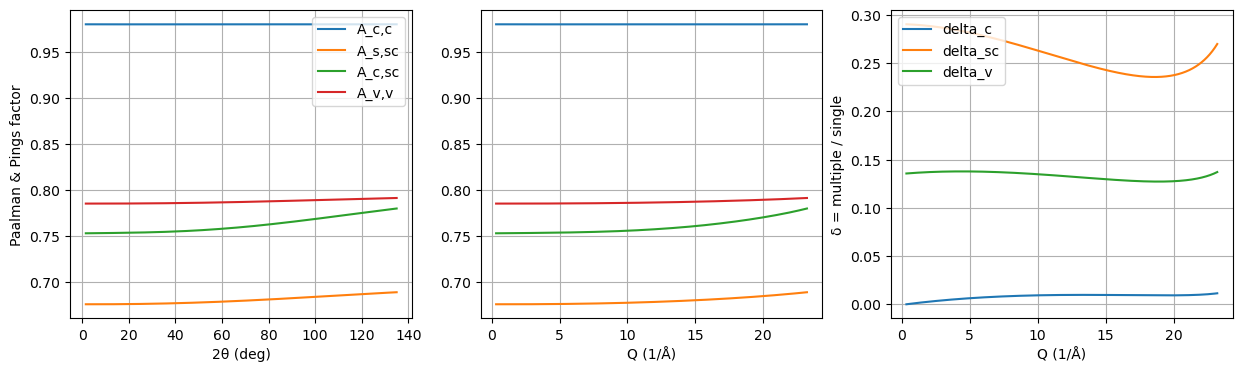

['A_c,c', 'A_c,c_err', 'A_c,sc', 'A_c,sc_err', 'A_s,sc', 'A_s,sc_err', 'delta_c', 'delta_c_err', 'delta_sc', 'delta_sc_err']


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for key, a in {**fs.A, **fv.A}.items():
    ax[0].plot(theta, a, label=key)
    ax[1].plot(q, a, label=key)
for key, d in {**fs.delta, **fv.delta}.items():
    ax[2].plot(q, d, label=key)
ax[0].set(xlabel="2θ (deg)", ylabel="Paalman & Pings factor"); ax[0].legend()
ax[1].set(xlabel="Q (1/Å)"); ax[2].set(xlabel="Q (1/Å)", ylabel="δ = multiple / single"); ax[2].legend()
plt.show()

for scale in ("q", "angle"):                       # factor files on both scales
    fs.save(f"{RESULTS}/Ni_powder_sample_factors_{scale}.dat", scale=scale, heading=["sample set-up"])
    fv.save(f"{RESULTS}/Ni_powder_vanadium_factors_{scale}.dat", scale=scale, heading=["vanadium set-up"])
x, table = fs.table("q")                            # the same as arrays: x = Q, table["A_s,sc"], ...
print(sorted(table))

## 3. The subtraction, step by step

With $M_C$ the measurement of configuration $C$:

1. **Background** (absorber method): $B_C = T_C\,I_E + (1-T_C)\,I_{ACE}$
   (the part of the furnace after the sample is seen only through the transmitted beam).
2. **Vanadium**: $I_V = \dfrac{M_v - B_v}{(1+\delta_v)\,A_{v,v}\,(1-P_v)}$ ($P_v$: Placzek), and
   the count rate per unit isotropic cross section $K = I_V/(P_v^{\rm scat}/4\pi)$.
3. **Multiple scattering** (absolute, $\delta$ refers to isotropic scatterers):
   $MS_C = \delta_C\,K\sum_{b\in C}A_{b,C}P_b/4\pi$.
4. **Paalman & Pings**, outermost body first:
   $I_C = (M_c - B_c - MS_c)/A_{c,c}$, $\quad I_S = (M_{sc} - B_{sc} - MS_{sc} - A_{c,sc}I_C)/A_{s,sc}$.
5. **Normalisation**: $d\sigma/d\Omega = I_S/(K\,n\langle L\rangle_s) + \sum_i c_i\sigma_i P_i/4\pi$.

Errors are propagated in quadrature. You can change any step here (e.g. another background
model) and keep the rest.

In [5]:
M = {k: data[k][1] for k in data}
E = {k: data[k][2] for k in data}

def background(f, cfg):
    t = f.T[f"T_{cfg}"]
    return t * M["empty"] + (1 - t) * M["absorber"], np.hypot(t * E["empty"], (1 - t) * E["absorber"])

# vanadium
V = Element("V")
P_v = placzek(theta, lam, V.weight, 300.0, "D4", "SERIES_EXPANSION", 0.0)
B_v, eB_v = background(fv, "v")
den = (1 + fv.delta["delta_v"]) * fv.A["A_v,v"] * (1 - P_v)
I_V = (M["vanadium"] - B_v) / den
I_V_err = np.hypot(E["vanadium"], eB_v) / den
K = I_V / (vanadium_setup.scattering_power("v") / (4 * math.pi))

# multiple scattering of each configuration
MS = {cfg: fs.delta[f"delta_{cfg}"] * K * sum(fs.A[f"A_{b},{cfg}"] * sample_setup.scattering_power(b) for b in cfg) / (4 * math.pi)
      for cfg in fs.configurations}

# container, then sample
B_c, eB_c = background(fs, "c")
I_C = (M["container"] - B_c - MS["c"]) / fs.A["A_c,c"]
I_C_err = np.hypot(E["container"], eB_c) / fs.A["A_c,c"]
B_sc, eB_sc = background(fs, "sc")
I_S = (M["sample"] - B_sc - MS["sc"] - fs.A["A_c,sc"] * I_C) / fs.A["A_s,sc"]
I_S_err = np.sqrt(E["sample"]**2 + eB_sc**2 + (fs.A["A_c,sc"] * I_C_err)**2) / fs.A["A_s,sc"]

# normalisation + Placzek of the sample
Ni = Element("Ni")
P_s = placzek(theta, lam, Ni.weight, m.TempK, "D4", "SERIES_EXPANSION", 0.0)
nL_s = fs.atoms_per_area["s"]
dcs = I_S / (K * nL_s) + Ni.sig_sca / (4 * math.pi) * P_s
# error: measurements of the sample set-up, and the vanadium (not smoothed) through K. K scales the
# intensity before the multiple-scattering subtraction (the MS terms are proportional to K)
Y_s = (M["sample"] - B_sc - fs.A["A_c,sc"] * (M["container"] - B_c) / fs.A["A_c,c"]) / fs.A["A_s,sc"]
dcs_err = np.hypot(I_S_err, Y_s * I_V_err / I_V) / (K * nL_s)
print(f"dsigma/dOmega at high Q: {dcs[q > 20].mean():.4f} barn/sr  (sigma_s/4pi = {Ni.sig_sca / 4 / math.pi:.4f})")

dsigma/dOmega at high Q: 1.4709 barn/sr  (sigma_s/4pi = 1.4722)


## 4. The same in one line, and comparison with the truth

`run_correction` does exactly the steps above (default `method="mcams"`). The intermediate
intensities are in `res.intensities` (`I_s`, `I_c`, `I_v`, `MS_sc`, ...), the backgrounds in
`res.backgrounds`, the factors in `res.factors` / `res.vanadium_factors`.

step by step vs run_correction: max |diff| of dsigma/dOmega = 3.552713678800501e-15
                                max |diff| of I_S           = 1.1641532182693481e-10
                                max |diff| of the errors    = 4.163336342344337e-17
vs truth: mean (dcs - true)/sigma = +0.007, rms = 1.001  (noise only: 0 and ~1)


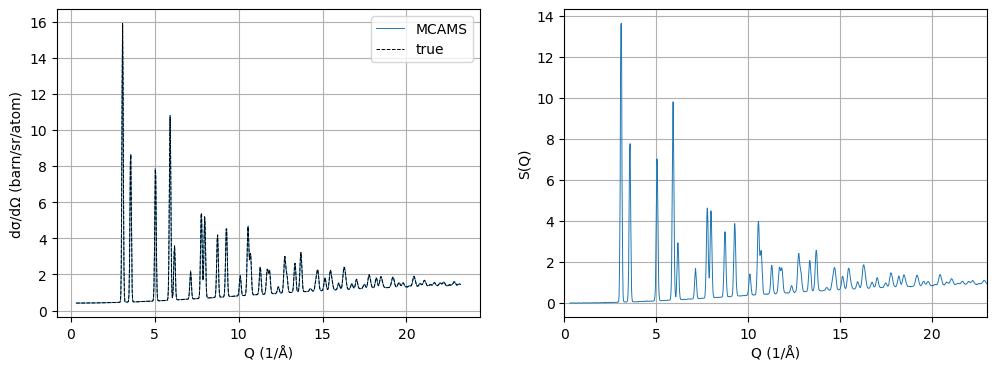

In [6]:
res = run_correction(m, files=files)                 # MCAMS, environment as background, absorber used
print("step by step vs run_correction: max |diff| of dsigma/dOmega =", np.abs(res.dcs - dcs).max())
print("                                max |diff| of I_S           =", np.abs(res.intensities["I_s"] - I_S).max())
print("                                max |diff| of the errors    =", np.abs(res.err - dcs_err).max())

truth = np.loadtxt(f"data/truth_{'angle' if INPUT == 'adat' else 'q'}.dat")
z = (res.dcs - truth[:, 2]) / res.err                # deviation in error bars
print(f"vs truth: mean (dcs - true)/sigma = {z.mean():+.3f}, rms = {z.std():.3f}  (noise only: 0 and ~1)")

sq = structure_factor(res, m, q_grid=m.qScale)
fig, ax = plt.subplots(1, 2)
ax[0].plot(res.q, res.dcs, lw=0.7, label="MCAMS")
ax[0].plot(res.q, truth[:, 2], "k--", lw=0.7, label="true")
ax[0].set(xlabel="Q (1/Å)", ylabel="dσ/dΩ (barn/sr/atom)"); ax[0].legend()
ax[1].plot(sq[:, 0], sq[:, 1], lw=0.7); ax[1].set(xlabel="Q (1/Å)", ylabel="S(Q)", xlim=(0, 23))
plt.show()

## 5. $I_S$ and $I_V$ on the Q and angle scales, files

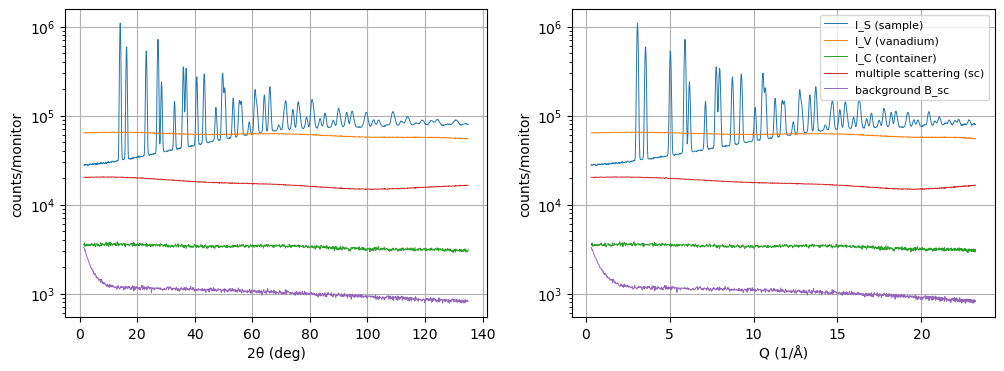

Ni_powder_mcams.soq
Ni_powder_mcams_dcs.dat
Ni_powder_mcams_intensities_angle.dat
Ni_powder_mcams_intensities_q.dat
Ni_powder_sample_factors_angle.dat
Ni_powder_sample_factors_q.dat
Ni_powder_vanadium_factors_angle.dat
Ni_powder_vanadium_factors_q.dat


In [7]:
fig, ax = plt.subplots(1, 2)
for x, lab in ((res.theta, "2θ (deg)"), (res.q, "Q (1/Å)")):
    i = 0 if x is res.theta else 1
    ax[i].plot(x, res.intensities["I_s"], lw=0.7, label="I_S (sample)")
    ax[i].plot(x, res.intensities["I_v"], lw=0.7, label="I_V (vanadium)")
    ax[i].plot(x, res.intensities["I_c"], lw=0.7, label="I_C (container)")
    ax[i].plot(x, res.intensities["MS_sc"], lw=0.7, label="multiple scattering (sc)")
    ax[i].plot(x, res.backgrounds["B_sc"], lw=0.7, label="background B_sc")
    ax[i].set(xlabel=lab, ylabel="counts/monitor", yscale="log")
ax[1].legend(fontsize=8); plt.show()

for scale in ("q", "angle"):
    res.save_intensities(f"{RESULTS}/Ni_powder_mcams_intensities_{scale}.dat", scale=scale)
# (the factor files were written in section 2; res.save_factors(basename, scale) does the same)
np.savetxt(f"{RESULTS}/Ni_powder_mcams_dcs.dat", np.column_stack([res.theta, res.q, res.dcs, res.err]),
           fmt="%14.7g", header="2theta(deg) Q(1/A) dsigma/dOmega(barn/sr/atom) error")
save_structure_factor(f"{RESULTS}/Ni_powder_mcams.soq", sq, ["Ni powder, MCAMS"])
print("\n".join(sorted(os.listdir(RESULTS))))

## 6. Optional: pycorrect (CORRECT 2.24) for comparison

pycorrect can describe this set-up (solid sample in contact with the container wall, solid
vanadium), but it **cannot use the absorber measurement**: the empty environment is subtracted
in full from every measurement. To separate the two effects, MCAMS is also run without the
absorber. pycorrect's factors are returned with the same keys (`A_s,sc`, `A_c,sc`, `A_c,c`,
`A_v,v`); its δ is a constant.

factor         MCAMS  pycorrect   (at 2theta = 20, 60, 120 deg)
A_s,sc        0.6762     0.6761   2theta=20.0
A_s,sc        0.6788     0.6792   2theta=60.0
A_s,sc        0.6870     0.6877   2theta=120.0
A_c,sc        0.7536     0.7530   2theta=20.0
A_c,sc        0.7579     0.7571   2theta=60.0
A_c,sc        0.7751     0.7747   2theta=120.0
A_c,c         0.9798     0.9799   2theta=20.0
A_c,c         0.9799     0.9799   2theta=60.0
A_c,c         0.9799     0.9799   2theta=120.0
A_v,v         0.7866     0.7869
delta_sc: MCAMS 0.2522 (total/total), pycorrect delta_sa 0.2341 (sample only)
delta_v : MCAMS 0.1321, pycorrect 0.1253

absorber effect (MCAMS without / with absorber - 1): -0.0029 to +0.0015


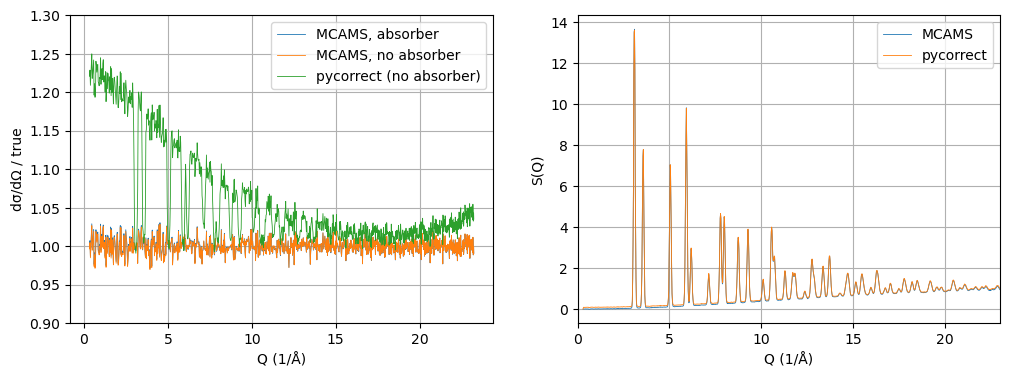

In [8]:
RUN_PYCORRECT = True
if RUN_PYCORRECT:
    no_abs = dict(files, absorber="")
    pyc = run_correction(m, method="pycorrect", files=no_abs, workdir=f"{RESULTS}/pycorrect_work")
    mc0 = run_correction(m, files=no_abs, factors=res.factors, vanadium_factors=res.vanadium_factors)

    print(f"{'factor':10s} {'MCAMS':>9s} {'pycorrect':>10s}   (at 2theta = 20, 60, 120 deg)")
    idx = [np.argmin(abs(theta - t)) for t in (20, 60, 120)]
    for key in ("A_s,sc", "A_c,sc", "A_c,c"):
        for i in idx:
            print(f"{key:10s} {res.factors.A[key][i]:9.4f} {pyc.factors.A[key][i]:10.4f}   2theta={theta[i]:.1f}")
    print(f"{'A_v,v':10s} {res.vanadium_factors.A['A_v,v'][idx[1]]:9.4f} {pyc.vanadium_factors.A['A_v,v'][idx[1]]:10.4f}")
    print(f"delta_sc: MCAMS {res.factors.delta['delta_sc'][idx[1]]:.4f} (total/total), "
          f"pycorrect delta_sa {float(pyc.pycorrect['delta_sa']):.4f} (sample only)")
    print(f"delta_v : MCAMS {res.vanadium_factors.delta['delta_v'][idx[1]]:.4f}, pycorrect {float(pyc.pycorrect['delta_va']):.4f}")
    eff = mc0.dcs / res.dcs - 1
    print(f"\nabsorber effect (MCAMS without / with absorber - 1): {eff.min():+.4f} to {eff.max():+.4f}")

    fig, ax = plt.subplots(1, 2)
    ax[0].plot(res.q, res.dcs / truth[:, 2], lw=0.6, label="MCAMS, absorber")
    ax[0].plot(mc0.q, mc0.dcs / truth[:, 2], lw=0.6, label="MCAMS, no absorber")
    ax[0].plot(pyc.q, pyc.dcs / truth[:, 2], lw=0.6, label="pycorrect (no absorber)")
    ax[0].set(xlabel="Q (1/Å)", ylabel="dσ/dΩ / true", ylim=(0.9, 1.3)); ax[0].legend()
    sq_p = structure_factor(pyc, m, q_grid=m.qScale)
    ax[1].plot(sq[:, 0], sq[:, 1], lw=0.6, label="MCAMS")
    ax[1].plot(sq_p[:, 0], sq_p[:, 1], lw=0.6, label="pycorrect")
    ax[1].set(xlabel="Q (1/Å)", ylabel="S(Q)", xlim=(0, 23)); ax[1].legend(); plt.show()

    for scale in ("q", "angle"):
        pyc.save_factors(f"{RESULTS}/Ni_powder_pycorrect_{scale}", scale=scale)
    save_structure_factor(f"{RESULTS}/Ni_powder_pycorrect.soq", sq_p, ["Ni powder, pycorrect"])

**Reading the comparison.** The synthetic data were generated with MCAMS factors, so MCAMS
recovers them by construction; what the comparison shows is the *size* of CORRECT's
approximations for this sample. The attenuation factors agree within 0.1 %; the difference comes
from the multiple scattering (CORRECT: one constant δ for the sample only, with an empirical
series for the higher orders; MCAMS: δ(2θ) of the whole configuration). It is largest at low Q,
where dσ/dΩ of a crystalline powder is small. Which is closer to reality was studied in
`docs/validation`: MCAMS agrees with brute-force Monte Carlo, CORRECT's higher orders are too low.
Here the absorber changes the result by only ~0.3 % (weak furnace, T_sc ≈ 0.81); it matters more
with strongly scattering environments or strongly absorbing samples.

## 7. The same without the notebook

See `README.md` in this folder. In short, from the `example` folder:

```bash
# ToScaNA command line (MCAMS by default; --method pycorrect for CORRECT)
python -m toscana.workflows.correct_cli Ni_powder.par --input qdat --scale both --outdir results/cli
python -m toscana.workflows.correct_cli Ni_powder.par --method pycorrect --outdir results/cli_pycorrect

# CORRECT's own command language (pycorrect), from the data folder
cd data && python -m toscana.corrections.pycorrect Ni_powder.com

# Python script doing what this notebook does
python run_example.py --input qdat
```